# Trabajo Práctico Final: Airbnb Price
# Notebook N°2: Machine Learning

El objetivo de esta notebook es desarrollar modelos de Machine Learning que realicecn la predicción del precio por noche de alojamientos de Airbnb en Estados Unidos, utilizando las características que se encuentran disponibles en el dataset.

Lo que haremos será cinco modelos (Regresión Lineal, Ridge, Lasso, Random Forest y XGBoost), primero con las variables originales y luego aplicando reducción de dimensionalidad con PCA. 

Como generalidad, para todos ellos se predice `log(precio)` y las métricas se calculan en dólares.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv("airbnb_us.csv")

print("Dimensiones:", df.shape)
df.head()

Dimensiones: (19309, 29)


,id,property_type,room_type,amenities,accommodates,bathrooms,bed_type,cancellation_policy,cleaning_fee,city,...,longitude,name,neighbourhood,number_of_reviews,review_scores_rating,thumbnail_url,zipcode,bedrooms,beds,price
0,13418779,House,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",Ki...",4,1.0,Real Bed,flexible,True,SF,...,-122.431619,Beautiful Flat in the Heart of SF!,Lower Haight,0,NaN,https://a0.muscache.com/im/pictures/72208dad-9...,94117.0,2.0,2.0,750.0
1,3808709,Apartment,Entire home/apt,"{TV,Internet,""Wireless Internet"",""Air conditio...",2,1.0,Real Bed,moderate,True,DC,...,-77.034596,Great studio in midtown DC,Columbia Heights,4,40.0,NaN,20009,0.0,1.0,115.0
2,12422935,Apartment,Private room,"{TV,""Wireless Internet"",Heating,""Smoke detecto...",2,1.0,Real Bed,strict,True,SF,...,-122.429526,Comfort Suite San Francisco,Noe Valley,3,100.0,https://a0.muscache.com/im/pictures/82509143-4...,94131,1.0,1.0,85.0
3,180792,House,Private room,"{TV,""Cable TV"",""Wireless Internet"",""Pets live ...",2,1.0,Real Bed,moderate,True,SF,...,-122.501095,Cozy Garden Studio - Private Entry,Richmond District,159,99.0,https://a0.muscache.com/im/pictures/0ed6c128-7...,94121,1.0,1.0,120.0
4,2658946,Apartment,Entire home/apt,"{TV,""Cable TV"",Internet,""Wireless Internet"",""A...",6,1.5,Real Bed,strict,True,DC,...,-77.031189,Charming 2 bdrm in trendy U/14th streets w/par...,U Street Corridor,13,89.0,NaN,20009,2.0,3.0,200.0


### **Limpieza y preparación de los datos**
Se aplican las decisiones tomadas en el EDA: se eliminan duplicados, se filtran los outliers del precio (percentiles 1 y 99, como en la clase de árboles de decisión), se tratan como faltantes los valores 0 en baños y camas, y se crean dos variables nuevas a partir de `amenities` y `host_since`.

In [20]:
# 1) Duplicados
df = df.drop_duplicates(subset='id')

# 2) Outliers del precio: nos quedamos con los valores entre los percentiles 1 y 99
p1, p99 = df['price'].quantile([0.01, 0.99])
df = df[(df['price'] >= p1) & (df['price'] <= p99)].copy()
print(f"Conservamos rango de precios: USD {p1:.0f} a USD {p99:.0f}")

# 3) 0 baños o 0 camas son datos anómalos: los pasamos a faltantes (se imputan más adelante)
df.loc[df['bathrooms'] == 0, 'bathrooms'] = np.nan
df.loc[df['beds'] == 0, 'beds'] = np.nan

# 4) Nuevas variables
df['num_amenities'] = df['amenities'].apply(lambda s: 0 if s == '{}' else s.count(',') + 1)
df['host_since'] = pd.to_datetime(df['host_since'], errors='coerce')
df['antiguedad_host_dias'] = (df['host_since'].max() - df['host_since']).dt.days

print("Dimensiones despues de la limpieza:", df.shape)

Conservamos rango de precios: USD 35 a USD 900
Dimensiones despues de la limpieza: (18610, 31)


In [3]:
variables = [
    'property_type',
    'room_type',
    'accommodates',
    'bathrooms',
    'bed_type',
    'cancellation_policy',
    'cleaning_fee',
    'city',
    'host_has_profile_pic',
    'host_identity_verified',
    'host_response_rate',
    'instant_bookable',
    'latitude',
    'longitude',
    'number_of_reviews',
    'review_scores_rating',
    'bedrooms',
    'beds',
    'num_amenities',
    'antiguedad_host_dias'
]

X = df[variables].copy()
y = df['price'].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (18949, 20)
Dimensiones de y: (18949,)


In [4]:
X['host_response_rate'] = (
    X['host_response_rate']
    .str.replace('%', '', regex=False)
    .astype(float)
)

print(X['host_response_rate'].head())

0      NaN
1    100.0
2    100.0
3    100.0
4    100.0
Name: host_response_rate, dtype: float64


### **Partición en train y test**

Dividimos el conjunto de datos en dos partes, utilizando una proporción 80/20

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

Datos de entrenamiento: (15159, 20)
Datos de prueba: (3790, 20)


### **Preprocesamiento**
Lo definimos dentro de un pipeline, para que tanto la imputación como el escalado y el OneHotEncoder se ajusten solo con los datos de entrenamiento (evitando hacer 'data leakage').

In [21]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

variables_numericas = [
    'accommodates',
    'bathrooms',
    'host_response_rate',
    'latitude',
    'longitude',
    'number_of_reviews',
    'review_scores_rating',
    'bedrooms',
    'beds',
    'num_amenities',
    'antiguedad_host_dias'
]

variables_categoricas = [
    'property_type',
    'room_type',
    'bed_type',
    'cancellation_policy',
    'city',
    'cleaning_fee',
    'host_has_profile_pic',
    'host_identity_verified',
    'instant_bookable'
]

preprocesamiento_numerico = Pipeline(steps=[
    ('imputacion', SimpleImputer(strategy='median')),
    ('escalado', StandardScaler())
])

preprocesamiento_categorico = Pipeline(steps=[
    ('imputacion', SimpleImputer(strategy='most_frequent')),
    ('codificacion', OneHotEncoder(handle_unknown='ignore'))
])

preprocesamiento = ColumnTransformer(transformers=[
    ('numericas', preprocesamiento_numerico, variables_numericas),
    ('categoricas', preprocesamiento_categorico, variables_categoricas)
])

### **Modelos**
Se entrenan los cinco modelos mencionados anteriormente:
- **Regresión Lineal:** modelo base.
- **Ridge y Lasso:** regresión lineal con penalización (L2 y L1). El valor de la penalización (alpha) se elige por validación cruzada.
- **Random Forest:** conjunto de árboles de decisión.
- **XGBoost:** boosting de árboles. Sus hiperparámetros se buscan con `RandomizedSearchCV`, (como en la clase de árboles de decisión).

Además se incluye un **modelo de referencia** que siempre predice la mediana, para saber cuánto mejoran los modelos respecto de no usar ninguna variable.

**Recordatorio:** Todos se entrenan para predecir `log(precio)` (con `TransformedTargetRegressor`) y las predicciones se devuelven ya en dólares.

In [7]:
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.compose import TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

# Búsqueda de hiperparámetros de XGBoost
param_dist_xgb = {
    'n_estimators': [100, 200, 300, 500],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0]
}

modelos = {
    'Regresión Lineal': LinearRegression(),
    'Ridge': RidgeCV(alphas=[0.01, 0.1, 1, 10, 100], cv=5),
    'Lasso': LassoCV(cv=5, random_state=42, max_iter=10000),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    'XGBoost': RandomizedSearchCV(
        XGBRegressor(objective='reg:squarederror', random_state=42, n_jobs=1),
        param_distributions=param_dist_xgb,
        n_iter=50, cv=3, scoring='neg_mean_squared_error',
        random_state=42, n_jobs=-1
    )
}


def crear_modelo(prep, regresor, usar_pca=False):
    """Arma: preprocesamiento -> (PCA) -> modelo, prediciendo log(precio)."""
    pasos = [('preprocesamiento', prep)]
    if usar_pca:
        pasos.append(('pca', PCA(n_components=0.95)))
    pasos.append(('modelo', regresor))
    return TransformedTargetRegressor(
        regressor=Pipeline(steps=pasos),
        func=np.log,
        inverse_func=np.exp
    )


def entrenar_y_evaluar(nombre, modelo):
    modelo.fit(X_train, y_train)
    pred = modelo.predict(X_test)
    metricas = {
        'Modelo': nombre,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    }
    return modelo, pred, metricas

In [8]:
entrenados = {}
predicciones = {}
resultados = []

modelos_a_entrenar = {'Referencia (mediana)': DummyRegressor(strategy='median'), **modelos}

for nombre, regresor in modelos_a_entrenar.items():
    modelo, pred, metricas = entrenar_y_evaluar(nombre, crear_modelo(preprocesamiento, regresor))
    entrenados[nombre] = modelo
    predicciones[nombre] = pred
    resultados.append(metricas)
    print("Entrenado:", nombre)

tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.round(3))

Entrenado: Referencia (mediana)
Entrenado: Regresión Lineal
Entrenado: Ridge
Entrenado: Lasso
Entrenado: Random Forest
Entrenado: XGBoost


,Modelo,MAE,RMSE,R2
0,Referencia (mediana),103.640,177.811,-0.131
1,Regresión Lineal,72.723,135.630,0.342
2,Ridge,72.777,135.645,0.342
3,Lasso,73.070,135.989,0.338
4,Random Forest,65.075,123.211,0.457
5,XGBoost,62.945,118.349,0.499


### **Hiperparámetros elegidos y variables relevantes**

In [10]:
# Mejores hiperparámetros encontrados
print("Mejor alpha Ridge:", entrenados['Ridge'].regressor_.named_steps['modelo'].alpha_)
print("Mejor alpha Lasso:", round(entrenados['Lasso'].regressor_.named_steps['modelo'].alpha_, 5))
print("Mejores hiperparámetros XGBoost:", entrenados['XGBoost'].regressor_.named_steps['modelo'].best_params_)

# Variables que Lasso eliminó (coeficiente igual a cero)
pipe_lasso = entrenados['Lasso'].regressor_
nombres = variables_numericas + list(pipe_lasso.named_steps['preprocesamiento'].named_transformers_['categoricas'].named_steps['codificacion'].get_feature_names(variables_categoricas))
coef_lasso = pd.Series(pipe_lasso.named_steps['modelo'].coef_, index=nombres)
print(f"\nLasso dejó en cero {(coef_lasso == 0).sum()} de {len(coef_lasso)} variables")
print("Variables eliminadas:", list(coef_lasso[coef_lasso == 0].index))

Mejor alpha Ridge: 0.01
Mejor alpha Lasso: 0.00036
Mejores hiperparámetros XGBoost: {'subsample': 0.7, 'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.7}

Lasso dejó en cero 23 de 62 variables
Variables eliminadas: ['latitude', 'property_type_Bungalow', 'property_type_Cabin', 'property_type_Camper/RV', 'property_type_Castle', 'property_type_Cave', 'property_type_Guesthouse', 'property_type_Hostel', 'property_type_Serviced apartment', 'property_type_Tent', 'property_type_Townhouse', 'property_type_Treehouse', 'property_type_Vacation home', 'property_type_Villa', 'property_type_Yurt', 'room_type_Private room', 'bed_type_Airbed', 'bed_type_Couch', 'bed_type_Pull-out Sofa', 'cancellation_policy_flexible', 'cancellation_policy_super_strict_60', 'city_DC', 'city_SF']


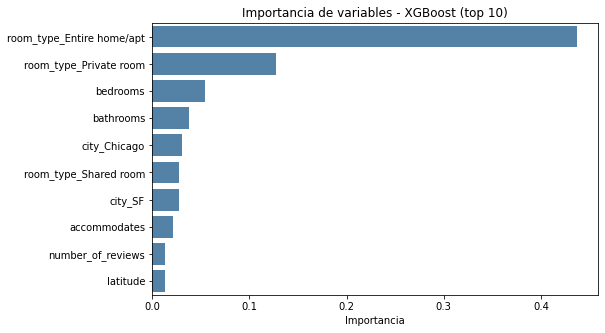

In [11]:
# Importancia de variables de XGBoost (top 10)
pipe_xgb = entrenados['XGBoost'].regressor_
importancia = pd.Series(
    pipe_xgb.named_steps['modelo'].best_estimator_.feature_importances_,
    index=nombres
).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=importancia.values, y=importancia.index, color='steelblue')
plt.title('Importancia de variables - XGBoost (top 10)')
plt.xlabel('Importancia')
plt.show()

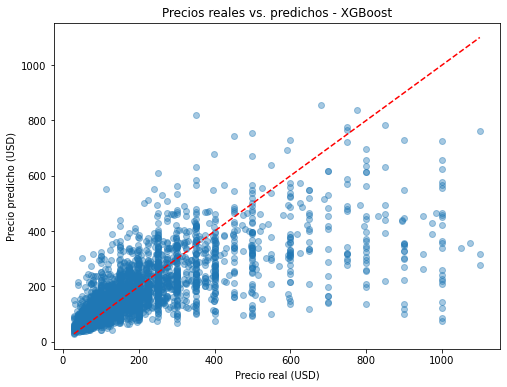

In [12]:
# Precios reales vs. predichos del mejor modelo (menor RMSE)
mejor = tabla_resultados.sort_values('RMSE').iloc[0]['Modelo']

plt.figure(figsize=(8,6))
plt.scatter(y_test, predicciones[mejor], alpha=0.4)
plt.xlabel('Precio real (USD)')
plt.ylabel('Precio predicho (USD)')
plt.title(f'Precios reales vs. predichos - {mejor}')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.show()

### **Reducción de dimensionalidad con PCA**
Luego del OneHotEncoder, el dataset pasa de 20 variables a bastantes más columnas. Aplicamos PCA (previo escalado) y nos quedamos con las componentes que explican el 95% de la varianza. Luego se vuelven a entrenar los mismos modelos.

Para PCA el OneHotEncoder debe devolver una matriz densa (`sparse_output=False`).

In [15]:
preprocesamiento_categorico_pca = Pipeline(steps=[
    ('imputacion', SimpleImputer(strategy='most_frequent')),
    ('codificacion', OneHotEncoder(
        handle_unknown='ignore',
        sparse=False
    ))
])

preprocesamiento_pca = ColumnTransformer(transformers=[
    ('numericas', preprocesamiento_numerico, variables_numericas),
    ('categoricas', preprocesamiento_categorico_pca, variables_categoricas)
])

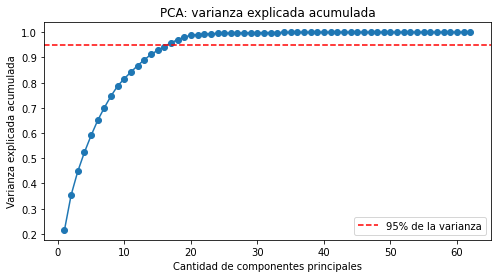

Columnas antes de PCA: 62
Componentes necesarias para el 95%: 17


In [16]:
# Varianza explicada acumulada por las componentes principales (ajustado solo con train)
X_train_prep = preprocesamiento_pca.fit_transform(X_train)
pca_completo = PCA().fit(X_train_prep)
varianza_acumulada = np.cumsum(pca_completo.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker='o')
plt.axhline(0.95, color='r', linestyle='--', label='95% de la varianza')
plt.xlabel('Cantidad de componentes principales')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA: varianza explicada acumulada')
plt.legend()
plt.show()

print("Columnas antes de PCA:", X_train_prep.shape[1])
print("Componentes necesarias para el 95%:", int(np.argmax(varianza_acumulada >= 0.95)) + 1)

In [17]:
entrenados_pca = {}
predicciones_pca = {}
resultados_pca = []

for nombre, regresor in modelos.items():
    modelo, pred, metricas = entrenar_y_evaluar(nombre + ' + PCA', crear_modelo(preprocesamiento_pca, regresor, usar_pca=True))
    entrenados_pca[nombre] = modelo
    predicciones_pca[nombre] = pred
    resultados_pca.append(metricas)
    print("Entrenado:", nombre, "+ PCA")

tabla_pca = pd.DataFrame(resultados_pca)
display(tabla_pca.round(3))

Entrenado: Regresión Lineal + PCA
Entrenado: Ridge + PCA
Entrenado: Lasso + PCA
Entrenado: Random Forest + PCA
Entrenado: XGBoost + PCA


,Modelo,MAE,RMSE,R2
0,Regresión Lineal + PCA,74.894,136.961,0.329
1,Ridge + PCA,74.899,136.979,0.329
2,Lasso + PCA,74.910,137.064,0.328
3,Random Forest + PCA,70.729,130.864,0.387
4,XGBoost + PCA,70.117,129.213,0.403


In [18]:
pca_usado = entrenados_pca['Regresión Lineal'].regressor_.named_steps['pca']
print("Cantidad de componentes utilizadas:", pca_usado.n_components_)
print("Varianza explicada:", pca_usado.explained_variance_ratio_.sum())

Cantidad de componentes utilizadas: 17
Varianza explicada: 0.9578278319350748


### **Comparación final**

In [19]:
comparacion_final = pd.concat([tabla_resultados, tabla_pca], ignore_index=True)
display(comparacion_final.round(3))

# Resumen automático
mejor_global = comparacion_final.sort_values('RMSE').iloc[0]
print(f"\nMejor modelo (menor RMSE): {mejor_global['Modelo']} | MAE = {mejor_global['MAE']:.2f} | RMSE = {mejor_global['RMSE']:.2f} | R2 = {mejor_global['R2']:.3f}")

print("\nEfecto de PCA sobre el RMSE de cada modelo (negativo = PCA mejora):")
for nombre in modelos.keys():
    sin = tabla_resultados.loc[tabla_resultados['Modelo'] == nombre, 'RMSE'].values[0]
    con = tabla_pca.loc[tabla_pca['Modelo'] == nombre + ' + PCA', 'RMSE'].values[0]
    print(f"  {nombre}: {sin:.2f} -> {con:.2f} ({con - sin:+.2f})")

,Modelo,MAE,RMSE,R2
0,Referencia (mediana),103.640,177.811,-0.131
1,Regresión Lineal,72.723,135.630,0.342
2,Ridge,72.777,135.645,0.342
3,Lasso,73.070,135.989,0.338
4,Random Forest,65.075,123.211,0.457
5,XGBoost,62.945,118.349,0.499
6,Regresión Lineal + PCA,74.894,136.961,0.329
7,Ridge + PCA,74.899,136.979,0.329
8,Lasso + PCA,74.910,137.064,0.328
9,Random Forest + PCA,70.729,130.864,0.387



Mejor modelo (menor RMSE): XGBoost | MAE = 62.95 | RMSE = 118.35 | R2 = 0.499

Efecto de PCA sobre el RMSE de cada modelo (negativo = PCA mejora):
  Regresión Lineal: 135.63 -> 136.96 (+1.33)
  Ridge: 135.64 -> 136.98 (+1.33)
  Lasso: 135.99 -> 137.06 (+1.08)
  Random Forest: 123.21 -> 130.86 (+7.65)
  XGBoost: 118.35 -> 129.21 (+10.86)


### **Conclusión de la comparación de modelos**

- La comparación se hizo sobre el mismo conjunto de test, con las métricas en dólares (MAE, RMSE y R²), y el resumen que se ve justo arriba indica cuál fue el mejor modelo y cómo cambió cada uno al aplicar PCA.
- Todos los modelos se comparan contra el modelo de referencia (que predice siempre la mediana): un modelo solo es útil si lo supera claramente.
- PCA es una técnica no supervisada. Esta resume las variables según su varianza sin tener en cuenta el precio, por lo que puede descartar información que sí es útil para predecirlo. Además, aplicarla sobre variables codificadas con OneHotEncoder tiene limitaciones. Por eso es habitual que no mejore, o incluso empeore levemente, el rendimiento; su ventaja principal es trabajar con menos dimensiones.
- Que PCA no haya mejorado los resultados no significa que esté mal aplicado: significa que, con esta configuración, conservar las variables originales produjo mejores predicciones.
- Lasso permite, además, identificar qué variables aportan poco al modelo (las que lleva a cero), y XGBoost muestra cuáles son las más importantes para predecir el precio.